In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [29]:
peng = sns.load_dataset('penguins')
print(peng.shape)
peng.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [30]:
peng.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [31]:
#rozkład etykiety
print(peng["species"].value_counts(normalize=True).round(3))

#braki w procentach
missing = peng.isna().mean().mul(100).round(1)
missing[missing > 0]

species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64


,0
bill_length_mm,0.6
bill_depth_mm,0.6
flipper_length_mm,0.6
body_mass_g,0.6
sex,3.2


In [32]:
#skale i skośność cech liczbowych
num_cols = ["bill_length_mm","bill_depth_mm","flipper_length_mm","body_mass_g"]
print(peng[num_cols].describe().round(1))
print("\nskośność:", peng[num_cols].skew().round(2).to_dict())

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%              39.2           15.6              190.0       3550.0
50%              44.4           17.3              197.0       4050.0
75%              48.5           18.7              213.0       4750.0
max              59.6           21.5              231.0       6300.0

skośność: {'bill_length_mm': 0.05, 'bill_depth_mm': -0.14, 'flipper_length_mm': 0.35, 'body_mass_g': 0.47}


In [33]:
#zależność cech od etykiety
print(peng.groupby("species")[num_cols].mean().round(3), "\n")
print(peng.pivot_table(index="species", columns="island", values="bill_length_mm").round(3), "\n")
print(peng.pivot_table(index="species", columns="sex", values="bill_length_mm").round(3), "\n")


           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie             38.791         18.346            189.954     3700.662
Chinstrap          48.834         18.421            195.824     3733.088
Gentoo             47.505         14.982            217.187     5076.016 

island     Biscoe   Dream  Torgersen
species                             
Adelie     38.975  38.502     38.951
Chinstrap     NaN  48.834        NaN
Gentoo     47.505     NaN        NaN 

sex        Female    Male
species                  
Adelie     37.258  40.390
Chinstrap  46.574  51.094
Gentoo     45.564  49.474 



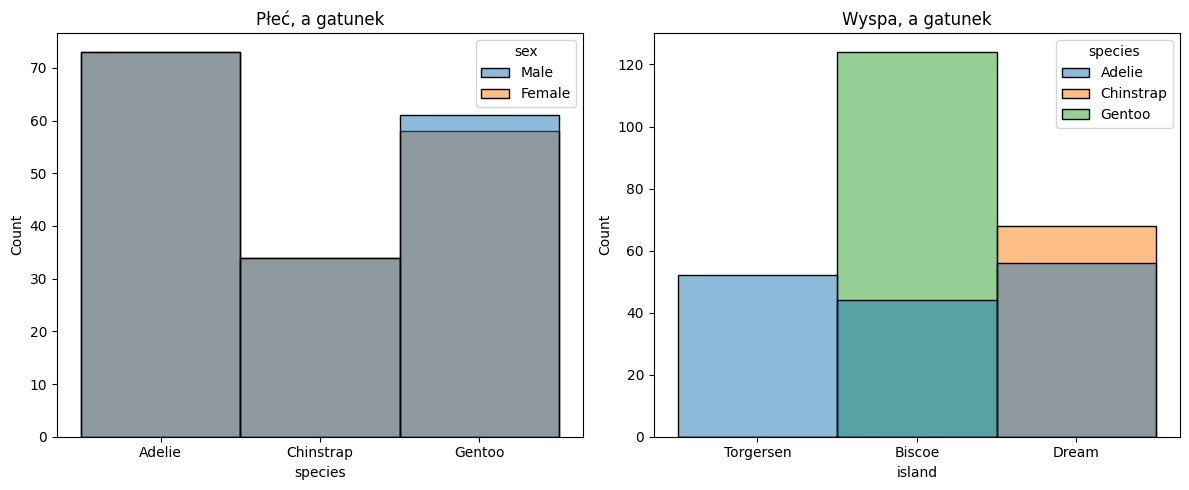

In [34]:
#wykres płeć, a gatunek; wyspa, a gatunek;

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=peng, x="species", hue = "sex", bins=3, ax=axes[0])
axes[0].set_title("Płeć, a gatunek")
sns.histplot(data=peng, x="island", hue = "species", bins=3, ax=axes[1])
axes[1].set_title("Wyspa, a gatunek")
fig.tight_layout()
plt.show()

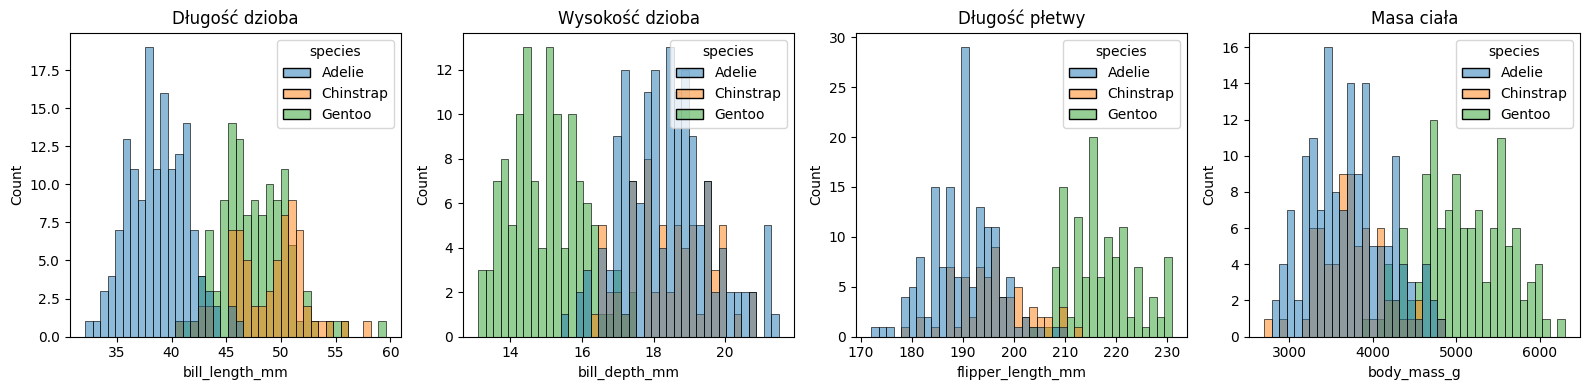

In [35]:
#wykresy w zaleznosci od parametrow
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
sns.histplot(data=peng, x="bill_length_mm", hue="species", bins=40, ax=axes[0])
axes[0].set_title("Długość dzioba")
sns.histplot(data=peng, x="bill_depth_mm", hue="species", bins=40, ax=axes[1])
axes[1].set_title("Wysokość dzioba")
sns.histplot(data=peng, x="flipper_length_mm", hue="species", bins=40, ax=axes[2])
axes[2].set_title("Długość płetwy")
sns.histplot(data=peng, x="body_mass_g", hue="species", bins=40, ax=axes[3])
axes[3].set_title("Masa ciała")
fig.tight_layout()
plt.show()

Procent klas:
 ~44% Adelie
 ~36% Gentoo
 ~20% Chinstrap
 baseline (DummyClassifier) osiagnie accuracy na poziomie ok. 44%

 Braki w danych są małe więc pomiarowe dane zostaną uzupełnione medianą, a płciowe najczestszą wartością

 Cechy liczbowe mają duże różnice w sklai dlatego zostanie zastosowana standaryzacja

 Wszystkie pomiary są ważne.

Train/test

In [36]:
features = ["island", "sex", "bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
target = "species"


X_train, X_test, y_train, y_test = train_test_split(
    peng[features], peng[target],
    test_size=0.25,
    stratify=peng[target],
    random_state=42,
)
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(3).to_dict())
print(y_test.value_counts(normalize=True).round(3).to_dict())

(258, 6) (86, 6)
{'Adelie': 0.442, 'Gentoo': 0.36, 'Chinstrap': 0.198}
{'Adelie': 0.442, 'Gentoo': 0.36, 'Chinstrap': 0.198}


In [37]:
#liczenie mediany i uzupelnienie plci do testu
num_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cat_features = ["island", "sex"]

prep = ColumnTransformer([
    ("num", make_pipeline (
        SimpleImputer(strategy="median"), StandardScaler()), num_features),

    ("cat",make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cat_features)
])

prep

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('standardscaler',
                                                  StandardScaler())]),
                                 ['bill_length_mm', 'bill_depth_mm',
                                  'flipper_length_mm', 'body_mass_g']),
                                ('cat',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['island', 'sex'])])

In [38]:
model = make_pipeline(prep,LogisticRegression(max_iter=1000))

model.fit(X_train, y_train)
print("Model wytrenowany jak trzeba")

Model wytrenowany jak trzeba


In [39]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
wyniki = pd.Series({
    "accuracy": model.score(X_test, y_test),
    "trening": model.score(X_train, y_train),
    "baseline": baseline.score(X_test, y_test),
})
print(wyniki.round(2))

accuracy    1.00
trening     0.99
baseline    0.44
dtype: float64


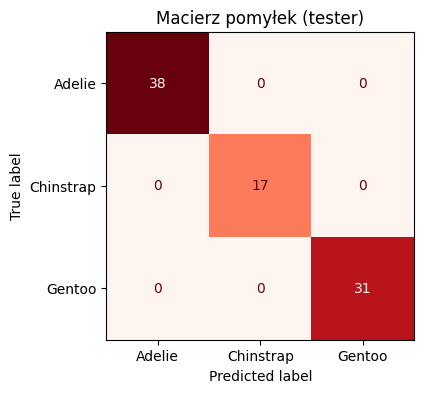

              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        38
   Chinstrap      1.000     1.000     1.000        17
      Gentoo      1.000     1.000     1.000        31

    accuracy                          1.000        86
   macro avg      1.000     1.000     1.000        86
weighted avg      1.000     1.000     1.000        86



In [40]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(
    model,
    X_test,
    y_test,
    ax=ax,
    cmap="Reds",
    colorbar=False
)
ax.set_title("Macierz pomyłek (tester)")
plt.show()
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))

In [41]:
def build(num, cat, add_indicator=False):

    transformers = [("liczby",
                     make_pipeline(SimpleImputer(strategy="median", add_indicator=add_indicator),
                                   StandardScaler()),
                     num)]
    if cat:
        transformers.append(("kategorie",
                             make_pipeline(SimpleImputer(strategy="most_frequent"),
                                                        OneHotEncoder(handle_unknown="ignore")),
                             cat))
    prep = ColumnTransformer(transformers)
    return make_pipeline(prep, LogisticRegression(max_iter=1000))



variants = {
    "pełny":                  build(num_features, cat_features),
    "z wskaznikami braków":         build(num_features, cat_features, add_indicator=True),
    "numerowe z płcią":              build(num_features, ["sex"]),
    "numerowe z wyspą":               build(num_features, ["island"]),
    "tylko numerowe":       build(num_features, []),
    "bez masy":               build([c for c in num_features if c != "body_mass_g"], cat_features),
    "dziób (dł, gł)":  build(["bill_length_mm", "bill_depth_mm"], []),
}

pd.Series({name: m.fit(X_train, y_train).score(X_test, y_test) for name, m in variants.items()}).round(3)


,0
pełny,1.000
z wskaznikami braków,1.000
numerowe z płcią,1.000
numerowe z wyspą,1.000
tylko numerowe,1.000
bez masy,0.988
"dziób (dł, gł)",0.942


Model osiąga wyniki bliskie 100%. WYnika z tego że same wymiary ciała są wystarczające do niemal bezbłędnego rozróżnienia gatunków.